<a href="https://colab.research.google.com/github/Huzaif005/Machine-Learning-External-/blob/main/Practical_3_Ubar_car_pynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [6]:
from google.colab import files
uploaded = files.upload()

Saving uber.csv to uber.csv


In [9]:
df = pd.read_csv("uber.csv")

print(df.head())
print(df.shape)

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [10]:
# Remove unnecessary column
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

# Remove missing values
df = df.dropna()

# Remove duplicate values
df = df.drop_duplicates()

# Remove invalid fare values
df = df[df['fare_amount'] > 0]

print(df.head())
print(df.shape)

                             key  fare_amount          pickup_datetime  \
0    2015-05-07 19:52:06.0000003          7.5  2015-05-07 19:52:06 UTC   
1    2009-07-17 20:04:56.0000002          7.7  2009-07-17 20:04:56 UTC   
2   2009-08-24 21:45:00.00000061         12.9  2009-08-24 21:45:00 UTC   
3    2009-06-26 08:22:21.0000001          5.3  2009-06-26 08:22:21 UTC   
4  2014-08-28 17:47:00.000000188         16.0  2014-08-28 17:47:00 UTC   

   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565         40.772647   
3        -73.976124        40.790844         -73.965316         40.803349   
4        -73.925023        40.744085         -73.973082         40.761247   

   passenger_count  
0                1  
1                1  
2                1  
3       

In [11]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df['fare_amount'] < lower) |
    (df['fare_amount'] > upper)
]

print("Number of Outliers:", len(outliers))

# Remove outliers
df = df[
    (df['fare_amount'] >= lower) &
    (df['fare_amount'] <= upper)
]

Number of Outliers: 17155


fare_amount          1.000000
pickup_longitude     0.000425
pickup_latitude      0.002573
dropoff_longitude   -0.002299
dropoff_latitude     0.000466
passenger_count      0.012618
Name: fare_amount, dtype: float64


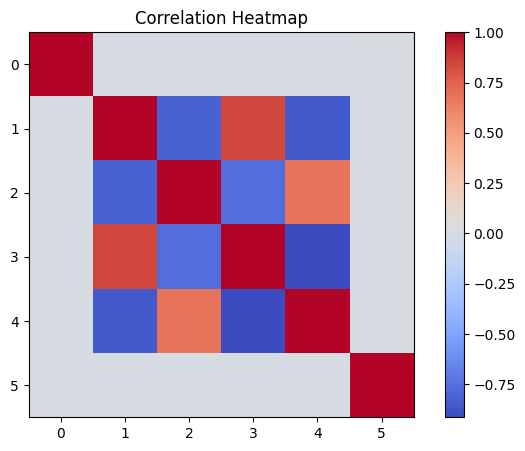

In [12]:
corr = df.select_dtypes(include=np.number).corr()

print(corr['fare_amount'])

plt.figure(figsize=(8, 5))
plt.imshow(corr, cmap='coolwarm')
plt.colorbar()
plt.title("Correlation Heatmap")
plt.show()

In [13]:
X = df[
    [
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude',
        'passenger_count'
    ]
]

y = df['fare_amount']

print(X.head())

   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565         40.772647   
3        -73.976124        40.790844         -73.965316         40.803349   
4        -73.925023        40.744085         -73.973082         40.761247   

   passenger_count  
0                1  
1                1  
2                1  
3                3  
4                5  


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [15]:
# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

# Ridge Regression
ridge = Ridge()
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

# Lasso Regression
lasso = Lasso()
lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)

print("All Models Trained Successfully!")

All Models Trained Successfully!


In [16]:
def evaluate(y_test, pred):

    r2 = r2_score(y_test, pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, pred)
    )

    mae = mean_absolute_error(y_test, pred)

    return r2, rmse, mae


print("Linear Regression:", evaluate(y_test, lr_pred))

print("Ridge Regression:", evaluate(y_test, ridge_pred))

print("Lasso Regression:", evaluate(y_test, lasso_pred))

Linear Regression: (6.66048690546317e-05, np.float64(4.175141541376116), 3.31472147436818)
Ridge Regression: (6.660459585461354e-05, np.float64(4.175141541946479), 3.314721474168144)
Lasso Regression: (-0.0001311921424891338, np.float64(4.175554463720892), 3.3149049483701667)


In [17]:
results = pd.DataFrame({
    'Model': ['Linear', 'Ridge', 'Lasso'],

    'R2 Score': [
        r2_score(y_test, lr_pred),
        r2_score(y_test, ridge_pred),
        r2_score(y_test, lasso_pred)
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, ridge_pred)),
        np.sqrt(mean_squared_error(y_test, lasso_pred))
    ],

    'MAE': [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, ridge_pred),
        mean_absolute_error(y_test, lasso_pred)
    ]
})

print(results)

    Model  R2 Score      RMSE       MAE
0  Linear  0.000067  4.175142  3.314721
1   Ridge  0.000067  4.175142  3.314721
2   Lasso -0.000131  4.175554  3.314905


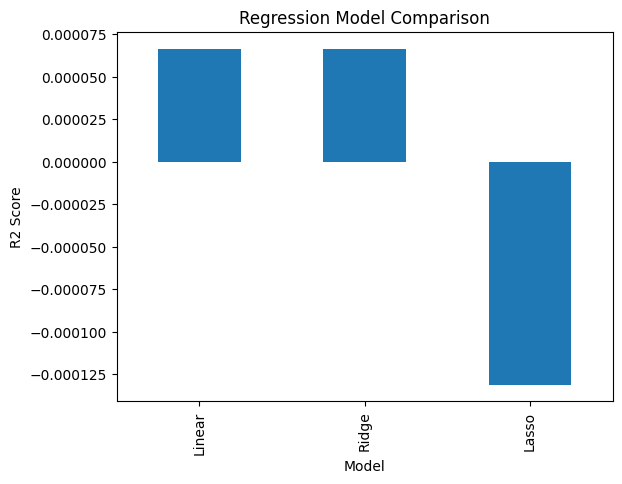

In [18]:
results.plot(
    x='Model',
    y='R2 Score',
    kind='bar',
    legend=False
)

plt.title("Regression Model Comparison")
plt.ylabel("R2 Score")
plt.show()